In [3]:
from src.utils.loading_data import load_symbol_from_dir
from pathlib import Path

# Folder containing all stock CSVs
stocks_dir = Path("data/stocks")

# Dictionary to hold all loaded DataFrames
all_stocks = {}

# Loop over every CSV file in the folder
for csv_file in sorted(stocks_dir.glob("*.csv")):
    symbol = csv_file.stem  # e.g. AAPL.csv → AAPL
    df = load_symbol_from_dir(stocks_dir, symbol)
    all_stocks[symbol] = df
    print(f"Loaded {symbol}: {len(df)} rows")

print(f"\n✅ Loaded {len(all_stocks)} stock symbols total.")


Loaded A: 5124 rows
Loaded AA: 14663 rows
Loaded AACG: 261 rows
Loaded AAL: 3653 rows
Loaded AAMC: 1837 rows
Loaded AAME: 10098 rows
Loaded AAN: 9431 rows
Loaded AAOI: 1640 rows
Loaded AAON: 6873 rows
Loaded AAP: 4616 rows
Loaded AAPL: 9909 rows
Loaded AAT: 2319 rows
Loaded AAU: 3594 rows
Loaded AAWW: 3622 rows
Loaded AAXN: 4729 rows
Loaded AB: 8056 rows
Loaded ABB: 4776 rows
Loaded ABBV: 1825 rows
Loaded ABC: 6293 rows
Loaded ABCB: 6514 rows
Loaded ABEO: 9968 rows
Loaded ABEV: 5808 rows
Loaded ABG: 4540 rows
Loaded ABIO: 5699 rows
Loaded ABM: 10098 rows
Loaded ABMD: 8236 rows
Loaded ABR: 4024 rows
Loaded ABT: 10098 rows
Loaded ABTX: 1128 rows
Loaded ABUS: 3194 rows
Loaded AC: 3075 rows
Loaded ACA: 353 rows
Loaded ACAD: 3989 rows
Loaded ACAM: 227 rows
Loaded ACAMU: 280 rows
Loaded ACB: 5055 rows
Loaded ACBI: 1111 rows
Loaded ACC: 3935 rows
Loaded ACCO: 3681 rows
Loaded ACEL: 269 rows
Loaded ACER: 4020 rows
Loaded ACGL: 6180 rows
Loaded ACGLO: 658 rows
Loaded ACGLP: 886 rows
Loaded ACH:

In [5]:
from src.utils.loading_data import load_symbol_from_dir
from pathlib import Path

# Folder containing all stock CSVs
etfs_dir = Path("data/etfs")

# Dictionary to hold all loaded DataFrames
all_etfs = {}

# Loop over every CSV file in the folder
for csv_file in sorted(etfs_dir.glob("*.csv")):
    symbol = csv_file.stem  
    df = load_symbol_from_dir(etfs_dir, symbol)
    all_etfs[symbol] = df
    print(f"Loaded {symbol}: {len(df)} rows")

print(f"\n✅ Loaded {len(all_etfs)} stock symbols total.")


Loaded AAAU: 410 rows
Loaded AADR: 2442 rows
Loaded AAXJ: 2927 rows
Loaded ABEQ: 50 rows
Loaded ACES: 443 rows
Loaded ACIO: 185 rows
Loaded ACSG: 332 rows
Loaded ACSI: 855 rows
Loaded ACT: 578 rows
Loaded ACWF: 1238 rows
Loaded ACWI: 3025 rows
Loaded ACWV: 2125 rows
Loaded ACWX: 3023 rows
Loaded ADME: 961 rows
Loaded ADRE: 4374 rows
Loaded AESR: 73 rows
Loaded AFIF: 377 rows
Loaded AFK: 2951 rows
Loaded AFLG: 82 rows
Loaded AFMC: 82 rows
Loaded AFSM: 82 rows
Loaded AFTY: 1274 rows
Loaded AGG: 4156 rows
Loaded AGGP: 981 rows
Loaded AGGY: 1192 rows
Loaded AGND: 1582 rows
Loaded AGQ: 2850 rows
Loaded AGT: 1106 rows
Loaded AGZ: 2866 rows
Loaded AGZD: 1582 rows
Loaded AIA: 3112 rows
Loaded AIEQ: 617 rows
Loaded AIIQ: 459 rows
Loaded AIQ: 473 rows
Loaded AIRR: 1527 rows
Loaded ALFA: 1972 rows
Loaded ALTS: 1379 rows
Loaded ALTY: 1189 rows
Loaded AMCA: 666 rows
Loaded AMLP: 2417 rows
Loaded AMOM: 219 rows
Loaded AMZA: 1384 rows
Loaded ANGL: 2007 rows
Loaded AOA: 2866 rows
Loaded AOK: 2860 rows

In [3]:
from src.utils.loading_data import load_nasdaq_metadata

meta = load_nasdaq_metadata("data/symbols_valid_meta.csv")
print(meta.head(3))


   nasdaq_traded symbol                            security_name  \
0           True      A  Agilent Technologies, Inc. Common Stock   
1           True     AA           Alcoa Corporation Common Stock   
2           True   AAAU             Perth Mint Physical Gold ETF   

  listing_exchange market_category    etf  round_lot_size  test_issue  \
0                N            <NA>  False           100.0       False   
1                N            <NA>  False           100.0       False   
2                P            <NA>   True           100.0       False   

  financial_status cqs_symbol nasdaq_symbol  nextshares  
0             <NA>          A             A       False  
1             <NA>         AA            AA       False  
2             <NA>       AAAU          AAAU       False  


In [4]:
from src.utils.data_inspection import missing_values_summary


meta_summary = missing_values_summary(meta)
print(meta_summary)


                            column  missing_count  missing_percentage
nasdaq_traded        nasdaq_traded              0                0.00
symbol                      symbol              0                0.00
security_name        security_name              0                0.00
listing_exchange  listing_exchange              0                0.00
market_category    market_category           4666               57.97
etf                            etf              0                0.00
round_lot_size      round_lot_size              0                0.00
test_issue              test_issue              0                0.00
financial_status  financial_status           4666               57.97
cqs_symbol              cqs_symbol           3383               42.03
nasdaq_symbol        nasdaq_symbol              0                0.00
nextshares              nextshares              0                0.00


In [5]:
import pandas as pd
def drop_cqs_symbol(df: pd.DataFrame) :
    """
    Drop the 'cqs_symbol' column from the metadata DataFrame if it exists.

    Returns a new DataFrame (does not modify the input in place).
    """
    if "cqs_symbol" in df.columns:
        df = df.drop(columns=["cqs_symbol"])
    return df

meta_dropped_cqs = drop_cqs_symbol(meta)
print(meta_dropped_cqs.columns)


Index(['nasdaq_traded', 'symbol', 'security_name', 'listing_exchange',
       'market_category', 'etf', 'round_lot_size', 'test_issue',
       'financial_status', 'nasdaq_symbol', 'nextshares'],
      dtype='object')


In [6]:
from src.utils.metadata_enrich import (
    load_nasdaq_symbol_directory,
    enrich_market_category_and_fin_status,
    add_readable_labels,
    missing_values_summary,
    exchange_missing_breakdown,
)

# 1) Load nasdaqlisted.txt
nasdaq_dir = load_nasdaq_symbol_directory("data/nasdaqlisted.txt")

# 2) Enrich your already-loaded `meta`
print("Before enrichment:")
print(missing_values_summary(meta_dropped_cqs)[["column","missing_count"]])

meta_enriched = enrich_market_category_and_fin_status(meta_dropped_cqs, nasdaq_dir)

print("\nAfter enrichment:")
print(missing_values_summary(meta_enriched)[["column","missing_count"]])

# 3) (Optional) Add readable labels
meta_enriched = add_readable_labels(meta_enriched)

# 4) (Optional) Quick diagnostics by exchange
print("\nMissing breakdown by exchange:")
print(exchange_missing_breakdown(meta_enriched))

# 5) Save for downstream work
meta_enriched.to_csv("data/metadata_enriched.csv", index=False)
print("\nSaved -> data/metadata_enriched.csv")


Before enrichment:
              column  missing_count
0      nasdaq_traded              0
1             symbol              0
2      security_name              0
3   listing_exchange              0
4    market_category           4666
5                etf              0
6     round_lot_size              0
7         test_issue              0
8   financial_status           4666
9      nasdaq_symbol              0
10        nextshares              0

After enrichment:
              column  missing_count
0      nasdaq_traded              0
1             symbol              0
2      security_name              0
3   listing_exchange              0
4    market_category           4583
5                etf              0
6     round_lot_size              0
7         test_issue              0
8   financial_status           4583
9      nasdaq_symbol              0
10        nextshares              0

Missing breakdown by exchange:
  listing_exchange  mc_missing  fs_missing  rows
3                

/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_12488/254933069.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


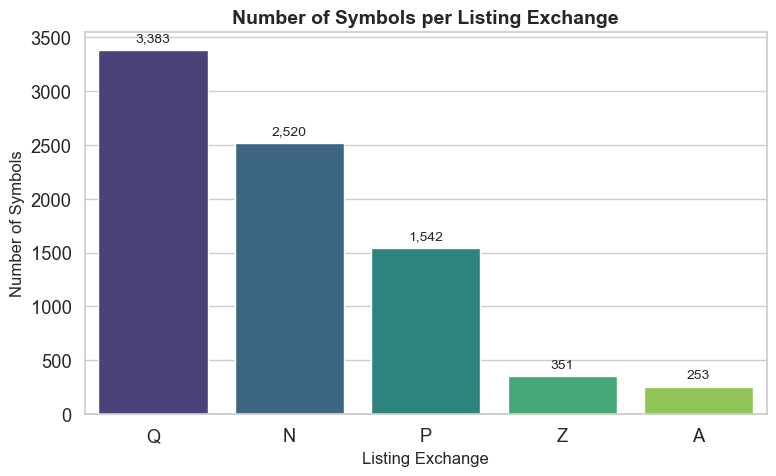

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plots look clean
sns.set(style="whitegrid", font_scale=1.2)

# Count how many symbols per listing exchange
exchange_counts = meta["listing_exchange"].value_counts().reset_index()
exchange_counts.columns = ["listing_exchange", "count"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=exchange_counts,
    x="listing_exchange",
    y="count",
    palette="viridis"
)

# Title and labels
plt.title("Number of Symbols per Listing Exchange", fontsize=14, weight="bold")
plt.xlabel("Listing Exchange", fontsize=12)
plt.ylabel("Number of Symbols", fontsize=12)

# Annotate bar tops
for i, row in exchange_counts.iterrows():
    ax.text(i, row["count"] + 50, f"{row['count']:,}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()


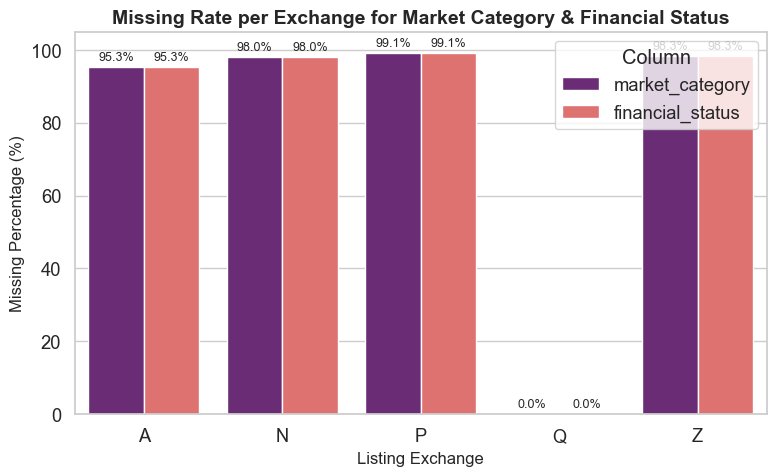

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Compute missing rates per listing_exchange for the 2 columns
cols_to_check = ["market_category", "financial_status"]

missing_rates = (
    meta_enriched.groupby("listing_exchange")[cols_to_check]
    .apply(lambda x: x.isna().mean() * 100)
    .reset_index()
    .melt(id_vars="listing_exchange", var_name="column", value_name="missing_percentage")
)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(
    data=missing_rates,
    x="listing_exchange",
    y="missing_percentage",
    hue="column",
    palette="magma"
)

plt.title("Missing Rate per Exchange for Market Category & Financial Status", fontsize=14, weight="bold")
plt.xlabel("Listing Exchange", fontsize=12)
plt.ylabel("Missing Percentage (%)", fontsize=12)
plt.legend(title="Column", loc="upper right")
plt.ylim(0, 105)

# Annotate bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=9, padding=3)

plt.tight_layout()
plt.show()


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_12488/3103935774.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=meta_q, x="market_category", palette="Set2")


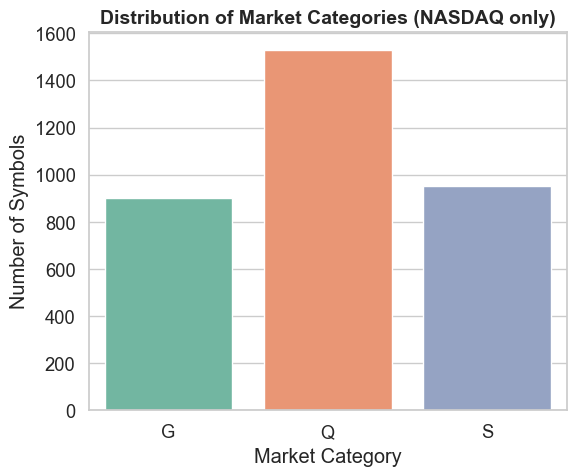

In [9]:
meta_q = meta_enriched[meta_enriched["listing_exchange"] == "Q"]

plt.figure(figsize=(6, 5))
sns.countplot(data=meta_q, x="market_category", palette="Set2")
plt.title("Distribution of Market Categories (NASDAQ only)", fontsize=14, weight="bold")
plt.xlabel("Market Category")
plt.ylabel("Number of Symbols")
plt.tight_layout()
plt.show()


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_12488/4150390790.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


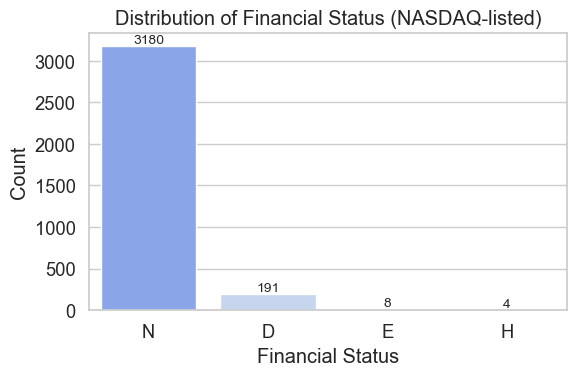

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Drop missing values to avoid NaN bar
data = meta_q.dropna(subset=["financial_status"])

plt.figure(figsize=(6,4))
ax = sns.countplot(
    data=data,
    x="financial_status",
    palette="coolwarm",
)

# add counts on top
for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="edge", fontsize=10)

plt.title("Distribution of Financial Status (NASDAQ-listed)")
plt.xlabel("Financial Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


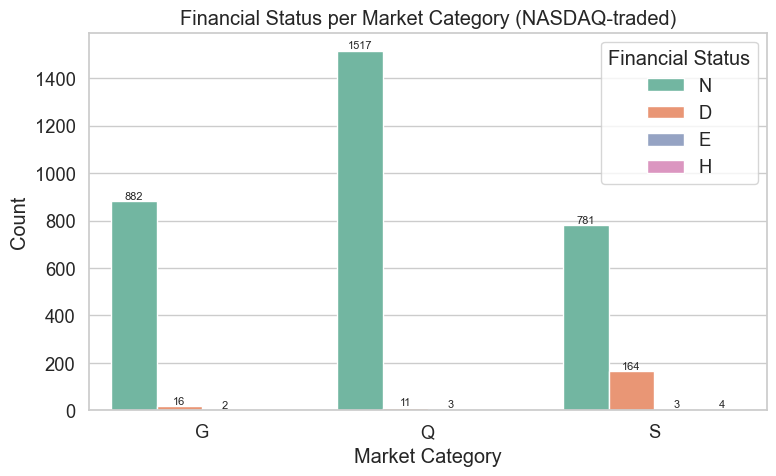

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# make sure you start from your NASDAQ-traded DataFrame
# (not necessarily meta_q, because meta_q was NASDAQ-listed)
# if you already have it:
# meta_traded = pd.read_csv("data/metadata_enriched_nasdaq_traded.csv")

# remove NaN entries in both columns
df = meta_q.dropna(subset=["market_category", "financial_status"])

plt.figure(figsize=(8,5))
ax = sns.countplot(
    data=df,
    x="market_category",
    hue="financial_status",
    palette="Set2"
)

plt.title("Financial Status per Market Category (NASDAQ-traded)")
plt.xlabel("Market Category")
plt.ylabel("Count")

# make legend clear
plt.legend(title="Financial Status")

# add labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="edge", fontsize=8)

plt.tight_layout()
plt.show()


In [12]:
from src.utils.data_inspection import dates_in_increasing_order
print("\n🔍 Checking if dates are in increasing order...")

for symbol, df in all_stocks.items():
    if dates_in_increasing_order(df):
        print(f"✅ {symbol}: dates are in increasing order.")
    else:
        print(f"⚠️ {symbol}: dates are NOT in increasing order!")



🔍 Checking if dates are in increasing order...
✅ A: dates are in increasing order.
✅ AA: dates are in increasing order.
✅ AACG: dates are in increasing order.
✅ AAL: dates are in increasing order.
✅ AAMC: dates are in increasing order.
✅ AAME: dates are in increasing order.
✅ AAN: dates are in increasing order.
✅ AAOI: dates are in increasing order.
✅ AAON: dates are in increasing order.
✅ AAP: dates are in increasing order.
✅ AAPL: dates are in increasing order.
✅ AAT: dates are in increasing order.
✅ AAU: dates are in increasing order.
✅ AAWW: dates are in increasing order.
✅ AAXN: dates are in increasing order.
✅ AB: dates are in increasing order.
✅ ABB: dates are in increasing order.
✅ ABBV: dates are in increasing order.
✅ ABC: dates are in increasing order.
✅ ABCB: dates are in increasing order.
✅ ABEO: dates are in increasing order.
✅ ABEV: dates are in increasing order.
✅ ABG: dates are in increasing order.
✅ ABIO: dates are in increasing order.
✅ ABM: dates are in increasing 

In [13]:
from src.utils.data_inspection import dates_in_increasing_order
print("\n🔍 Checking if dates are in increasing order...")

for symbol, df in all_etfs.items():
    if dates_in_increasing_order(df):
        print(f"✅ {symbol}: dates are in increasing order.")
    else:
        print(f"⚠️ {symbol}: dates are NOT in increasing order!")



🔍 Checking if dates are in increasing order...
✅ AAAU: dates are in increasing order.
✅ AADR: dates are in increasing order.
✅ AAXJ: dates are in increasing order.
✅ ABEQ: dates are in increasing order.
✅ ACES: dates are in increasing order.
✅ ACIO: dates are in increasing order.
✅ ACSG: dates are in increasing order.
✅ ACSI: dates are in increasing order.
✅ ACT: dates are in increasing order.
✅ ACWF: dates are in increasing order.
✅ ACWI: dates are in increasing order.
✅ ACWV: dates are in increasing order.
✅ ACWX: dates are in increasing order.
✅ ADME: dates are in increasing order.
✅ ADRE: dates are in increasing order.
✅ AESR: dates are in increasing order.
✅ AFIF: dates are in increasing order.
✅ AFK: dates are in increasing order.
✅ AFLG: dates are in increasing order.
✅ AFMC: dates are in increasing order.
✅ AFSM: dates are in increasing order.
✅ AFTY: dates are in increasing order.
✅ AGG: dates are in increasing order.
✅ AGGP: dates are in increasing order.
✅ AGGY: dates are i

In [14]:
from src.utils.data_inspection import show_date_ranges
show_date_ranges(all_stocks)



📅 Date ranges for all stocks:

A: from 1999-11-18 → 2020-04-01
AA: from 1962-01-02 → 2020-04-01
AACG: from 2019-03-11 → 2020-04-01
AAL: from 2005-09-27 → 2020-04-01
AAMC: from 2012-12-13 → 2020-04-01
AAME: from 1980-03-17 → 2020-04-01
AAN: from 1982-11-04 → 2020-04-01
AAOI: from 2013-09-26 → 2020-04-01
AAON: from 1992-12-16 → 2020-04-01
AAP: from 2001-11-29 → 2020-04-01
AAPL: from 1980-12-12 → 2020-04-01
AAT: from 2011-01-13 → 2020-04-01
AAU: from 2005-12-20 → 2020-04-01
AAWW: from 2005-11-09 → 2020-04-01
AAXN: from 2001-06-08 → 2020-04-01
AB: from 1988-04-14 → 2020-04-01
ABB: from 2001-04-06 → 2020-04-01
ABBV: from 2013-01-02 → 2020-04-01
ABC: from 1995-04-04 → 2020-04-01
ABCB: from 1994-05-19 → 2020-04-01
ABEO: from 1980-09-19 → 2020-04-01
ABEV: from 1997-03-05 → 2020-04-01
ABG: from 2002-03-21 → 2020-04-01
ABIO: from 1997-08-08 → 2020-04-01
ABM: from 1980-03-17 → 2020-04-01
ABMD: from 1987-07-29 → 2020-04-01
ABR: from 2004-04-07 → 2020-04-01
ABT: from 1980-03-17 → 2020-04-01
ABTX: 

In [15]:
from src.utils.data_inspection import show_date_ranges
show_date_ranges(all_etfs)



📅 Date ranges for all stocks:

AAAU: from 2018-08-15 → 2020-04-01
AADR: from 2010-07-21 → 2020-04-01
AAXJ: from 2008-08-15 → 2020-04-01
ABEQ: from 2020-01-22 → 2020-04-01
ACES: from 2016-01-27 → 2020-04-01
ACIO: from 2019-07-10 → 2020-04-01
ACSG: from 2018-12-06 → 2020-04-01
ACSI: from 2016-11-07 → 2020-04-01
ACT: from 2017-12-13 → 2020-04-01
ACWF: from 2015-05-04 → 2020-04-01
ACWI: from 2008-03-28 → 2020-04-01
ACWV: from 2011-10-20 → 2020-04-01
ACWX: from 2008-04-01 → 2020-04-01
ADME: from 2016-06-08 → 2020-04-01
ADRE: from 2002-11-14 → 2020-04-01
AESR: from 2019-12-17 → 2020-04-01
AFIF: from 2018-10-02 → 2020-04-01
AFK: from 2008-07-14 → 2020-04-01
AFLG: from 2019-12-04 → 2020-04-01
AFMC: from 2019-12-04 → 2020-04-01
AFSM: from 2019-12-04 → 2020-04-01
AFTY: from 2015-03-12 → 2020-04-01
AGG: from 2003-09-29 → 2020-04-01
AGGP: from 2016-05-10 → 2020-04-01
AGGY: from 2015-07-09 → 2020-04-01
AGND: from 2013-12-18 → 2020-04-01
AGQ: from 2008-12-04 → 2020-04-01
AGT: from 2010-11-08 → 2020

In [16]:
from src.utils.data_inspection import ends_before
early_ending_stocks = ends_before(all_stocks, cutoff_date="2020-04-01")


⚠️ The following stocks end before 2020-04-01:
  - CARR#
  - LGF.B
  - SDPI
  - ZIONW


In [17]:
from src.utils.data_inspection import ends_before
early_ending_etfs = ends_before(all_etfs, cutoff_date="2020-04-01")


⚠️ The following stocks end before 2020-04-01:
  - FDG


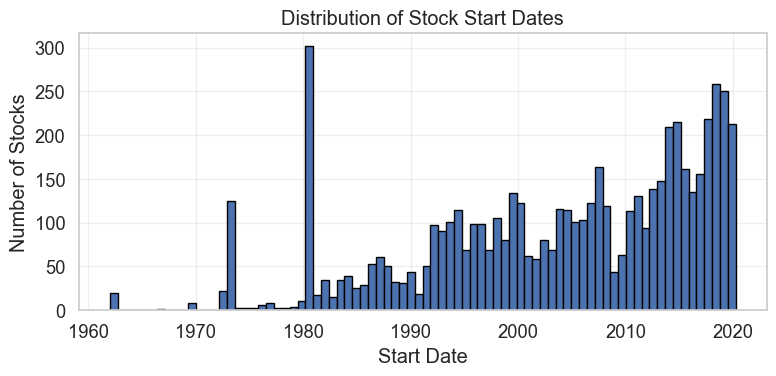


📅 Stocks starting on each exact date:

1962-01-02: 20 stock(s)
1966-07-05: 1 stock(s)
1970-01-02: 8 stock(s)
1972-06-01: 21 stock(s)
1972-08-25: 1 stock(s)
1973-01-02: 1 stock(s)
1973-02-21: 88 stock(s)
1973-02-22: 4 stock(s)
1973-02-23: 1 stock(s)
1973-03-13: 1 stock(s)
1973-05-02: 3 stock(s)
1973-05-03: 26 stock(s)
1973-05-08: 1 stock(s)
1973-10-23: 1 stock(s)
1974-04-09: 1 stock(s)
1974-12-17: 1 stock(s)
1975-02-07: 1 stock(s)
1975-06-06: 1 stock(s)
1975-06-12: 1 stock(s)
1975-10-31: 1 stock(s)
1975-11-17: 4 stock(s)
1976-06-17: 1 stock(s)
1976-07-08: 1 stock(s)
1976-08-18: 1 stock(s)
1977-01-03: 7 stock(s)
1977-06-17: 1 stock(s)
1977-12-05: 1 stock(s)
1978-01-03: 1 stock(s)
1978-04-12: 1 stock(s)
1978-04-26: 1 stock(s)
1978-10-31: 1 stock(s)
1978-12-29: 1 stock(s)
1979-04-06: 1 stock(s)
1979-05-15: 1 stock(s)
1979-10-15: 1 stock(s)
1980-01-02: 6 stock(s)
1980-02-27: 1 stock(s)
1980-02-28: 1 stock(s)
1980-03-11: 1 stock(s)
1980-03-17: 257 stock(s)
1980-03-18: 12 stock(s)
1980-03-19

In [18]:
from src.utils.data_inspection import plot_start_date_distribution, start_date_counts
# Plot with more bins (e.g., 80) and print per-date counts
counts = plot_start_date_distribution(all_stocks, bins=80)

# Or, just get the counts without plotting:
per_date = start_date_counts(all_stocks)


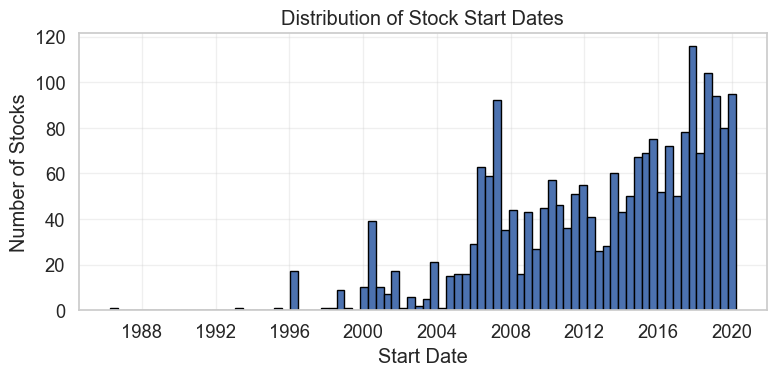


📅 Stocks starting on each exact date:

1986-04-03: 1 stock(s)
1993-01-29: 1 stock(s)
1995-05-04: 1 stock(s)
1996-03-18: 17 stock(s)
1998-01-20: 1 stock(s)
1998-06-30: 1 stock(s)
1998-12-22: 9 stock(s)
1999-03-10: 1 stock(s)
1999-11-23: 1 stock(s)
2000-01-03: 6 stock(s)
2000-01-18: 2 stock(s)
2000-02-01: 1 stock(s)
2000-05-08: 1 stock(s)
2000-05-12: 1 stock(s)
2000-05-19: 3 stock(s)
2000-05-26: 10 stock(s)
2000-06-05: 1 stock(s)
2000-06-16: 4 stock(s)
2000-06-19: 1 stock(s)
2000-06-20: 2 stock(s)
2000-06-21: 1 stock(s)
2000-06-22: 1 stock(s)
2000-06-23: 1 stock(s)
2000-06-28: 1 stock(s)
2000-07-14: 2 stock(s)
2000-07-28: 8 stock(s)
2000-07-31: 1 stock(s)
2000-08-04: 1 stock(s)
2000-10-02: 6 stock(s)
2000-10-10: 1 stock(s)
2000-10-27: 1 stock(s)
2000-12-08: 1 stock(s)
2001-02-02: 1 stock(s)
2001-02-12: 1 stock(s)
2001-02-26: 1 stock(s)
2001-03-19: 1 stock(s)
2001-05-17: 1 stock(s)
2001-06-15: 1 stock(s)
2001-07-10: 1 stock(s)
2001-07-13: 1 stock(s)
2001-07-17: 1 stock(s)
2001-08-02: 2 s

In [19]:
from src.utils.data_inspection import plot_start_date_distribution, start_date_counts
# Plot with more bins (e.g., 80) and print per-date counts
counts = plot_start_date_distribution(all_etfs, bins=80)

# Or, just get the counts without plotting:
per_date = start_date_counts(all_etfs)


In [20]:
from src.utils.data_inspection import missing_rates_from_dict
missing_per_stock, missing_stocks = missing_rates_from_dict(all_stocks)

print("🔹 Missing rates per stock:")
print(missing_per_stock.head())

print("\n🔹 Overall missing rates for stocks:")
print(missing_stocks)


🔹 Missing rates per stock:
        Date  Open  High  Low  Close  Adj Close  Volume  Symbol
Symbol                                                         
A        0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AA       0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AACG     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAL      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAMC     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0

🔹 Overall missing rates for stocks:
           Total Missing Rate (%)
Date                     0.000000
Open                     0.002682
High                     0.002682
Low                      0.002682
Close                    0.002682
Adj Close                0.002682
Volume                   0.002682
Symbol                   0.000000


In [21]:
from src.utils.data_inspection import missing_rates_from_dict
missing_per_etf, missing_etfs = missing_rates_from_dict(all_etfs)

print("🔹 Missing rates per etf:")
print(missing_per_etf.head())

print("\n🔹 Overall missing rates for etfs:")
print(missing_etfs)


🔹 Missing rates per etf:
        Date  Open  High  Low  Close  Adj Close  Volume  Symbol
Symbol                                                         
AAAU     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AADR     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAXJ     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
ABEQ     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
ACES     0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0

🔹 Overall missing rates for etfs:
           Total Missing Rate (%)
Date                      0.00000
Open                      0.00086
High                      0.00086
Low                       0.00086
Close                     0.00086
Adj Close                 0.00086
Volume                    0.00086
Symbol                    0.00000


In [22]:
# ---- ZERO VALUE ANALYSIS ----
from src.utils.data_inspection import zero_rates_from_dict

zero_per_symbol_stocks, zero_overall_stocks = zero_rates_from_dict(all_stocks)
print("📊 Zero value rates per symbol (STOCKS):")
print(zero_per_symbol_stocks.head())

print("\n📈 Overall zero value rates (STOCKS):")
print(zero_overall_stocks)



📊 Zero value rates per symbol (STOCKS):
        Open  High  Low  Close  Adj Close    Volume
Symbol                                             
A        0.0   0.0  0.0    0.0        0.0  0.000000
AA       0.0   0.0  0.0    0.0        0.0  0.006820
AACG     0.0   0.0  0.0    0.0        0.0  0.000000
AAL      0.0   0.0  0.0    0.0        0.0  0.000000
AAMC     0.0   0.0  0.0    0.0        0.0  5.498095

📈 Overall zero value rates (STOCKS):
           Total Zero Rate (%)
Open                  4.876015
High                  0.000149
Low                   0.000149
Close                 0.000149
Adj Close             0.000149
Volume                5.781714


In [23]:
# For ETFs
zero_per_symbol_etfs, zero_overall_etfs = zero_rates_from_dict(all_etfs)
print("\n📊 Zero value rates per symbol (ETFs):")
print(zero_per_symbol_etfs.head())

print("\n📈 Overall zero value rates (ETFs):")
print(zero_overall_etfs)



📊 Zero value rates per symbol (ETFs):
        Open  High  Low  Close  Adj Close     Volume
Symbol                                              
AAAU     0.0   0.0  0.0    0.0        0.0   0.000000
AADR     0.0   0.0  0.0    0.0        0.0  12.407862
AAXJ     0.0   0.0  0.0    0.0        0.0   0.068329
ABEQ     0.0   0.0  0.0    0.0        0.0   0.000000
ACES     0.0   0.0  0.0    0.0        0.0   0.677201

📈 Overall zero value rates (ETFs):
           Total Zero Rate (%)
Open                  0.035834
High                  0.000582
Low                   0.000582
Close                 0.000000
Adj Close             0.000000
Volume                5.464106


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_missing_counts_over_time(all_data: dict[str, pd.DataFrame], label: str = "Stocks"):
    """
    Plot the total number of missing values over time across all symbols.

    Parameters
    ----------
    all_data : dict[str, pd.DataFrame]
        Dictionary where key = symbol, value = DataFrame of that symbol (must have a 'Date' column).
    label : str, optional
        Label for the plot title (e.g., 'Stocks' or 'ETFs').
    """
    missing_by_date = []

    for symbol, df in all_data.items():
        if "Date" not in df.columns:
            continue

        df = df.copy()
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

        # Count missing values per row (sum over columns)
        df["missing_count"] = df.isna().sum(axis=1)

        # Aggregate per date (in case of duplicates)
        daily_missing = df.groupby("Date")["missing_count"].sum().reset_index()
        missing_by_date.append(daily_missing)

    # Combine all symbols' missing counts per date
    merged = pd.concat(missing_by_date, ignore_index=True)
    total_missing_per_date = merged.groupby("Date")["missing_count"].sum().reset_index()

    # Sort by date
    total_missing_per_date = total_missing_per_date.sort_values("Date")

    # Plot
    plt.figure(figsize=(12, 5))
    plt.plot(total_missing_per_date["Date"], total_missing_per_date["missing_count"], color="orange")
    plt.title(f"🕒 Total Missing Values Over Time ({label})")
    plt.xlabel("Date")
    plt.ylabel("Number of Missing Values")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    return total_missing_per_date


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_14176/40185071.py:45: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


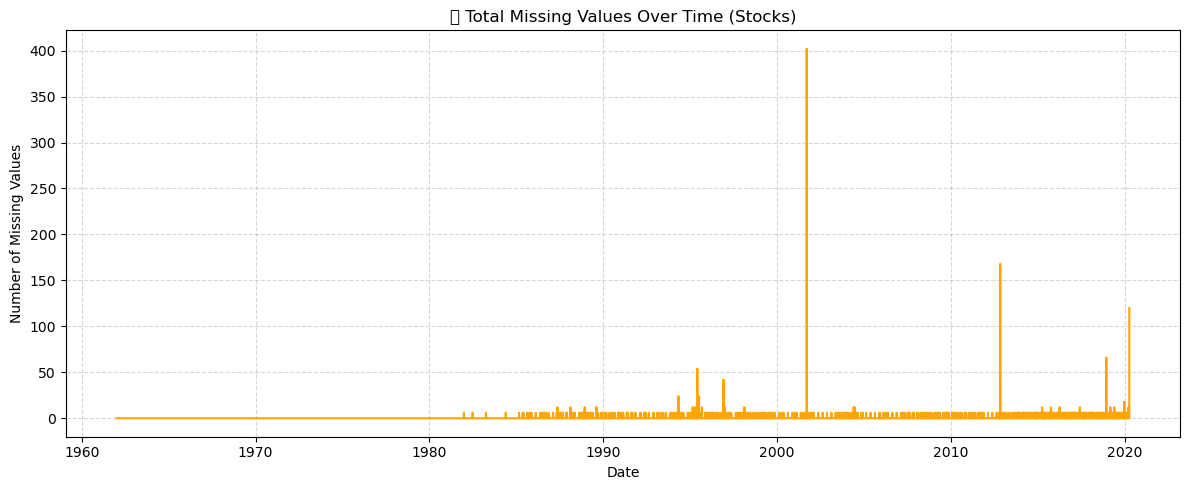

,Date,missing_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14712,2020-03-27,0
14713,2020-03-30,0
14714,2020-03-31,0
14715,2020-04-01,0


In [4]:
plot_missing_counts_over_time(all_stocks, label="Stocks")

/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_14176/40185071.py:45: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


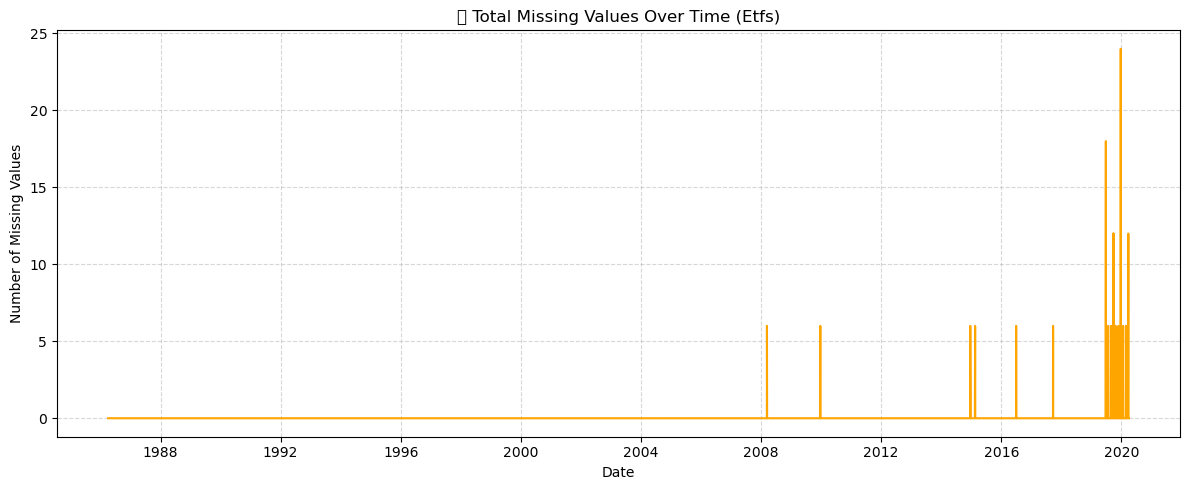

,Date,missing_count
0,1986-04-03,0
1,1986-04-04,0
2,1986-04-07,0
3,1986-04-08,0
4,1986-04-09,0
...,...,...
8564,2020-03-26,0
8565,2020-03-27,0
8566,2020-03-30,0
8567,2020-03-31,0


In [6]:
plot_missing_counts_over_time(all_etfs, label="Etfs")

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_zero_counts_over_time(all_data: dict[str, pd.DataFrame], label: str = "Stocks"):
    """
    Plot the total number of 0.0 values over time across all symbols.

    Parameters
    ----------
    all_data : dict[str, pd.DataFrame]
        Dictionary where key = symbol, value = DataFrame of that symbol (must have a 'Date' column).
    label : str, optional
        Label for the plot title (e.g., 'Stocks' or 'ETFs').
    """
    zero_by_date = []

    for symbol, df in all_data.items():
        if "Date" not in df.columns:
            continue

        df = df.copy()
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

        # Select only numeric columns
        numeric_df = df.select_dtypes(include=[np.number])

        # Count zero values per row
        df["zero_count"] = (numeric_df == 0).sum(axis=1)

        # Aggregate by date (sum across rows for that symbol)
        daily_zero = df.groupby("Date")["zero_count"].sum().reset_index()
        zero_by_date.append(daily_zero)

    # Combine all symbols’ zero counts per date
    merged = pd.concat(zero_by_date, ignore_index=True)
    total_zero_per_date = merged.groupby("Date")["zero_count"].sum().reset_index()

    # Sort by date
    total_zero_per_date = total_zero_per_date.sort_values("Date")

    # Plot
    plt.figure(figsize=(12, 5))
    plt.plot(total_zero_per_date["Date"], total_zero_per_date["zero_count"], color="royalblue")
    plt.title(f"🕒 Total Zero Values Over Time ({label})")
    plt.xlabel("Date")
    plt.ylabel("Number of Zero Values")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    return total_zero_per_date


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_14176/1239004322.py:49: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


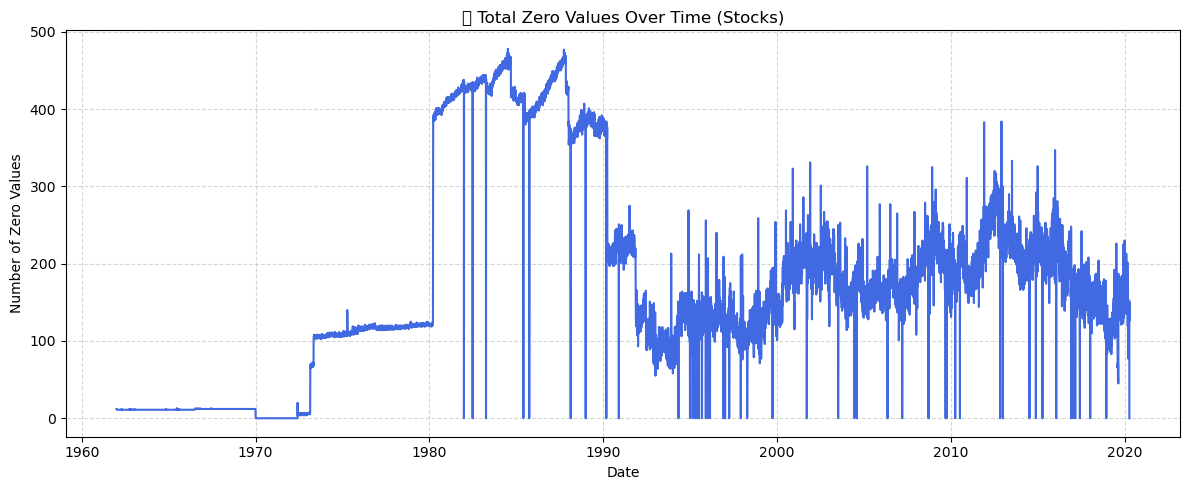

,Date,zero_count
0,1962-01-02,12
1,1962-01-03,11
2,1962-01-04,11
3,1962-01-05,11
4,1962-01-08,11
...,...,...
14712,2020-03-27,125
14713,2020-03-30,152
14714,2020-03-31,126
14715,2020-04-01,150


In [8]:
plot_zero_counts_over_time(all_stocks, label="Stocks")


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_14176/1239004322.py:49: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


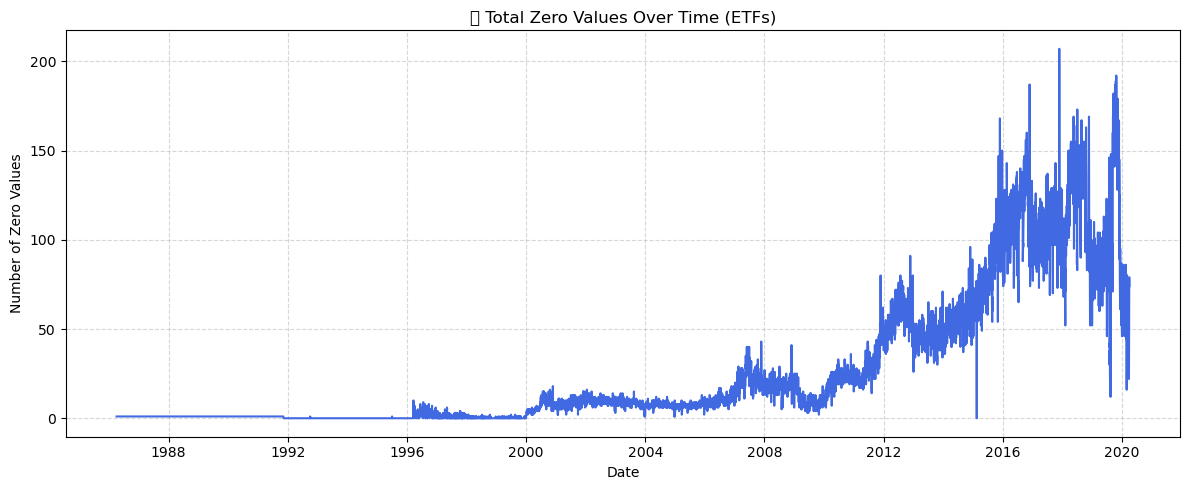

,Date,zero_count
0,1986-04-03,1
1,1986-04-04,1
2,1986-04-07,1
3,1986-04-08,1
4,1986-04-09,1
...,...,...
8564,2020-03-26,61
8565,2020-03-27,22
8566,2020-03-30,73
8567,2020-03-31,79


In [9]:
plot_zero_counts_over_time(all_etfs, label="ETFs")
